# HTSK, LogTSK and TSK: from a first fit to the result of the article

This notebook goes, one step at a time, from a first fit with the defaults to the
setting of

> Y. Cui, D. Wu and Y. Xu, "Curse of dimensionality for TSK fuzzy neural networks:
> explanation and solutions", *IJCNN*, 2021.

on Vowel, one of the datasets of the article. It is a short version of the script
`examples/reproductions/htsk_2021.py`, which runs the full protocol (two datasets, ten
repetitions); here three repetitions are enough to see the result, and the whole
notebook runs in about a minute.

1. settings and reproducibility;
2. the data;
3. a first fit with the defaults;
4. the setting of the article, on the same split;
5. what the fitted model looks like;
6. the three families, three repetitions, next to the article.

## 1. Settings and reproducibility

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import highfis
from highfis import HTSKClassifier, LogTSKClassifier, TSKClassifier

In [2]:
SEED = 0
REPETITIONS = 3
THREADS = 4

FAMILIES = {"TSK": TSKClassifier, "LogTSK": LogTSKClassifier, "HTSK": HTSKClassifier}

# Table II of the article, Vowel: mean test accuracy in percent over ten repetitions.
ARTICLE = {"TSK": 87.91, "LogTSK": 85.42, "HTSK": 88.32}

torch.set_num_threads(THREADS)
torch.use_deterministic_algorithms(True)
highfis.set_mf_cache_enabled(False)

## 2. The data

Vowel has 990 recordings of eleven English vowels, described by ten features. On OpenML
the first two columns identify the speaker and are left out.

In [3]:
bunch = fetch_openml(data_id=307, as_frame=False, parser="liac-arff")
features = bunch.data[:, 2:].astype(np.float32)
class_names, labels = np.unique(bunch.target, return_inverse=True)

print(f"{features.shape[0]} samples, {features.shape[1]} features, {len(class_names)} classes")
print(f"samples per class: {np.bincount(labels).tolist()}")

990 samples, 10 features, 11 classes
samples per class: [90, 90, 90, 90, 90, 90, 90, 90, 90, 90, 90]


The article keeps 30% of the samples for testing, and 10% of the training part as a
validation set. The inputs are standardized with the mean and the deviation of the
training part.

In [4]:
x_train, x_test, y_train, y_test = train_test_split(
    features, labels, test_size=0.3, random_state=SEED, stratify=labels
)
x_train, x_val, y_train, y_val = train_test_split(x_train, y_train, test_size=0.1, random_state=SEED)

scaler = StandardScaler().fit(x_train)
x_train, x_val, x_test = scaler.transform(x_train), scaler.transform(x_val), scaler.transform(x_test)

print(f"training: {len(x_train)}, validation: {len(x_val)}, test: {len(x_test)}")

training: 623, validation: 70, test: 297


## 3. A first fit with the defaults

The defaults of `HTSKClassifier` are meant for a quick first fit: three rules and 100
epochs.

In [5]:
first = HTSKClassifier(random_state=SEED).fit(x_train, y_train)

print(f"rules: {first.model_.n_rules}")
print(f"training accuracy: {100 * first.score(x_train, y_train):.1f}%")
print(f"test accuracy: {100 * first.score(x_test, y_test):.1f}%")

rules: 3
training accuracy: 83.6%
test accuracy: 73.7%


The model is far from the 88% of the article, and does not fit the training part well
either. The loss is still falling at the last epoch, and three rules are few for eleven
classes:

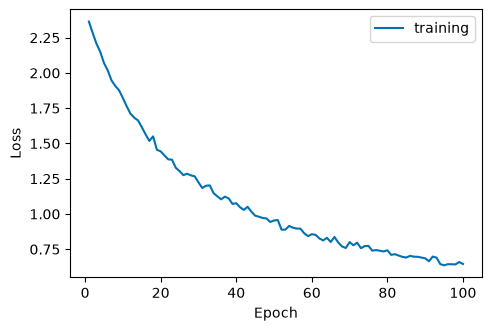

In [6]:
first.plot_history()

## 4. The setting of the article

The article uses 30 rules, with centres from k-means and spreads drawn around one, and
trains for at most 200 epochs, stopping when the accuracy on the validation set has not
improved for 20 epochs and keeping the best model. The batch has 512 samples.

In [7]:
model = HTSKClassifier(
    n_mfs=30,
    sigma_init="constant",
    epochs=200,
    patience=20,
    learning_rate=0.01,
    batch_size=512 if len(x_train) >= 512 else min(len(x_train), 60),
    random_state=SEED,
)
model.fit(x_train, y_train, x_val=x_val, y_val=y_val)

print(f"rules: {model.model_.n_rules}")
print(f"training accuracy: {100 * model.score(x_train, y_train):.1f}%")
print(f"test accuracy: {100 * model.score(x_test, y_test):.1f}%")

rules: 30
training accuracy: 98.4%
test accuracy: 91.6%


The training now reaches a plateau before it stops:

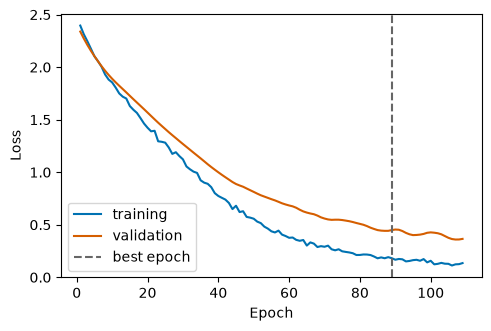

In [8]:
model.plot_history()

## 5. What the fitted model looks like

The confusion matrix on the test part, with the margin of the decisions:

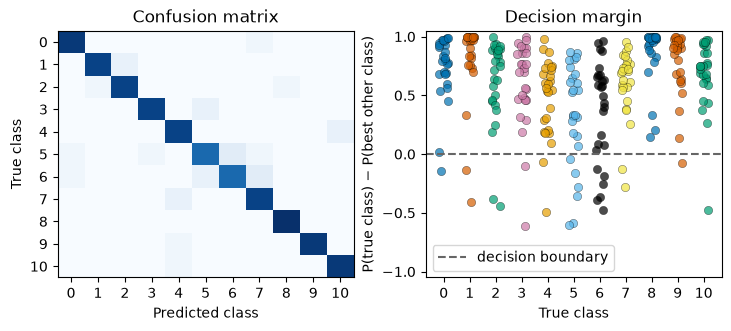

In [9]:
model.plot_diagnostics(x_test, y_test)

Each rule covers a region of the input space. The mean weight of each rule on the samples
of each class shows which rules serve which vowels:

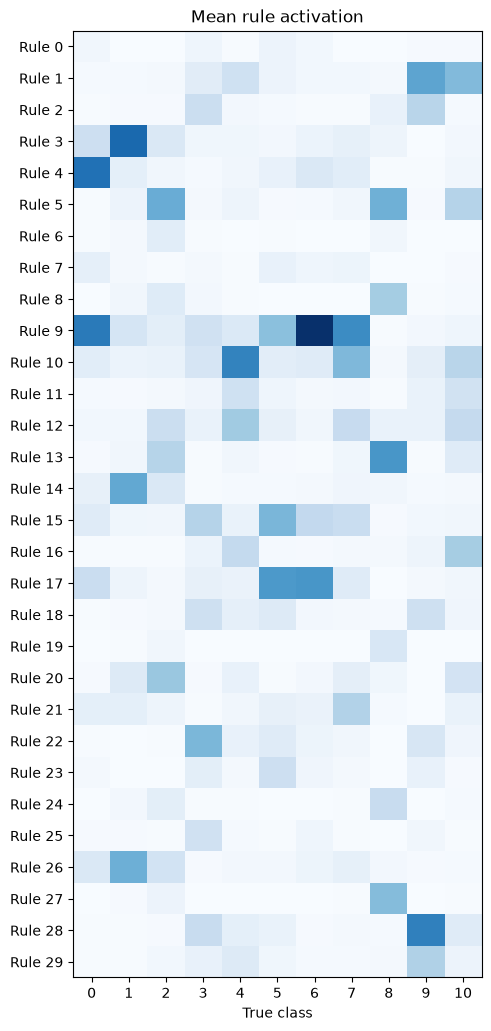

In [10]:
model.plot_rule_activation(x_test, y_test)

The fuzzy sets of four of the features. With centres from k-means, each rule has its own
set on every feature:

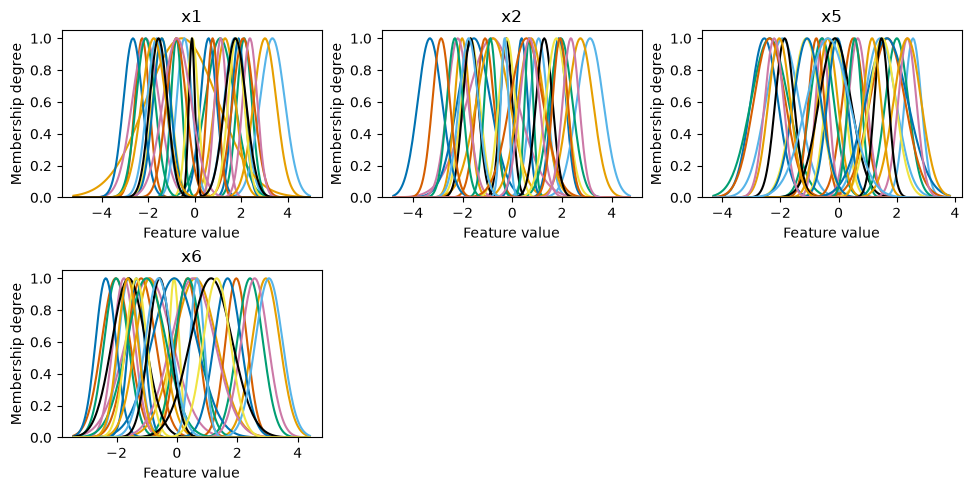

In [11]:
model.plot_memberships(max_features=4)

The numerical check of the rule weights. HTSK normalizes the firing strengths in the
logarithmic domain, so the weights do not underflow, and about how many rules share a
sample is given by `effective_rules`:

In [12]:
report = model.firing_diagnostics(x_test)
print(f"samples with the same weight on every rule: {100 * report['uniform_fraction']:.0f}%")
print(f"effective number of rules per sample: {report['effective_rules']:.1f} of {report['n_rules']}")

samples with the same weight on every rule: 0%
effective number of rules per sample: 5.6 of 30


A summary of the model and of its training, in one call:

In [13]:
model.summary()

HTSKClassifier
  task               classification, 11 classes
  features           10 seen in fit, 10 used by the model
  rules              30 (rule base: coco)
  fuzzy sets         30 per feature, GaussianMF
  firing strength    RuleLayer, T-norm GMeanTNorm
  defuzzifier        SoftmaxLogDefuzzifier
  consequents        ClassificationConsequentLayer
  parameters         4230 trainable (600 antecedent, 3630 consequent)
Training (batch size 512)
  phase     epochs  rate  loss first -> last  accuracy  val. loss  best epoch
  training     109  0.01    2.3957 -> 0.1353    0.9888     0.3656          89

How the rules produce the prediction of the first test sample. The output is the sum of
what each rule contributes, and the predicted class is the one with the largest value:

In [14]:
model.explain(x_test[0])

Prediction: 10
Output, the sum of the contributions of the 30 rules: 0: -4.84, 1: -3.55,
    2: +3.52, 3: -3.45, 4: +2.86, 5: -3.69, 6: -3.45, 7: -2.27, 8: -0.71,
    9: -3.31, 10: +5.27
Rule 5, weight 0.48: contributes 0: -2.39, 1: -2.30, 2: +2.10, 3: -1.85,
    4: +0.37, 5: -1.78, 6: -1.82, 7: -2.26, 8: -0.17, 9: -1.88, 10: +3.02
    IF x1 is level 8 of 30 AND x2 is level 9 of 30 AND x3 is level 23 of 30
       AND x4 is level 27 of 30 AND x5 is level 30 of 30
       AND x6 is level 21 of 30 AND x7 is level 15 of 30 AND x8 is level 4 of 30
       AND x9 is level 3 of 30 AND x10 is level 15 of 30
Rule 20, weight 0.37: contributes 0: -2.33, 1: -1.37, 2: +1.38, 3: -1.30,
    4: +2.32, 5: -1.54, 6: -1.40, 7: -0.52, 8: -0.53, 9: -1.08, 10: +1.86
    IF x1 is level 6 of 30 AND x2 is level 18 of 30 AND x3 is level 21 of 30
       AND x4 is level 19 of 30 AND x5 is level 28 of 30 AND x6 is level 7 of 30
       AND x7 is level 6 of 30 AND x8 is level 6 of 30 AND x9 is level 7 of 30
       AND

How well the rules cover the samples: for each sample, the mean membership degree in its
best-matching rule. A test sample with a coverage well below the training samples would
lie outside the region the rules were built on:

In [15]:
inside, outside = model.coverage(x_train), model.coverage(x_test)
print(f"training part: min {inside.min():.2f}, median {np.median(inside):.2f}")
print(f"test part:     min {outside.min():.2f}, median {np.median(outside):.2f}")

training part: min 0.30, median 0.46
test part:     min 0.30, median 0.45


## 6. The three families next to the article

The same setting for the vanilla TSK, LogTSK and HTSK, on three random splits. The
article reports the mean of ten; the script runs all ten.

In [16]:
results = {family: [] for family in FAMILIES}

for family, estimator in FAMILIES.items():
    for repetition in range(REPETITIONS):
        seed = SEED + repetition
        a_train, a_test, b_train, b_test = train_test_split(
            features, labels, test_size=0.3, random_state=seed, stratify=labels
        )
        a_train, a_val, b_train, b_val = train_test_split(a_train, b_train, test_size=0.1, random_state=seed)
        scaler = StandardScaler().fit(a_train)

        fitted = estimator(
            n_mfs=30,
            sigma_init="constant",
            epochs=200,
            patience=20,
            learning_rate=0.01,
            batch_size=512 if len(a_train) >= 512 else min(len(a_train), 60),
            random_state=seed,
        )
        fitted.fit(scaler.transform(a_train), b_train, x_val=scaler.transform(a_val), y_val=b_val)
        results[family].append(100 * fitted.score(scaler.transform(a_test), b_test))

print(f"{'family':7s} {'article':>8s} {'highFIS':>8s} {'std':>6s}")
for family, scores in results.items():
    print(f"{family:7s} {ARTICLE[family]:8.2f} {np.mean(scores):8.2f} {np.std(scores):6.2f}")

family   article  highFIS    std
TSK        87.91    88.66   5.99
LogTSK     85.42    84.18   3.78
HTSK       88.32    88.10   7.17


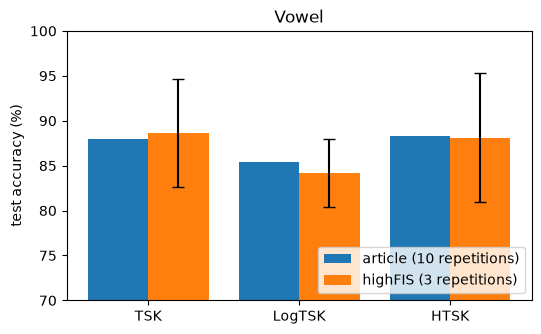

In [17]:
positions = np.arange(len(FAMILIES))
means = [np.mean(results[family]) for family in FAMILIES]
deviations = [np.std(results[family]) for family in FAMILIES]

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(positions - 0.2, [ARTICLE[family] for family in FAMILIES], width=0.4, label="article (10 repetitions)")
ax.bar(positions + 0.2, means, width=0.4, yerr=deviations, capsize=4, label=f"highFIS ({REPETITIONS} repetitions)")
ax.set_xticks(positions, list(FAMILIES))
ax.set_ylim(70, 100)
ax.set_ylabel("test accuracy (%)")
ax.set_title("Vowel")
ax.legend(loc="lower right")
plt.show()

The three families are within the spread between repetitions of the values of the
article. With ten repetitions, as in the script, the means are 87.81, 84.28 and 89.97.